# Plot

In this notebook we plot all the main figures in the text.

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import numpy as np
import matplotlib.pyplot as plt
import os
import drape_lib as dl
from qutip import Bloch, basis, sigmax, sigmay, sigmaz, sesolve
%config InlineBackend.figure_formats = ['retina']
plt.rcParams['figure.dpi'] = 200   # tweak to taste

In [2]:
# ============================================================
#  CENTRAL STYLE  —  edit everything here; all figures pull from this
# ============================================================

# ---- font sizes (pt) -------------------------------------------------
FS_LABEL   = 7    # axis labels + body text   (axes.labelsize / font.size)
FS_TICK    = 7    # major / minor tick labels (x/ytick.labelsize)
FS_LEGEND  = 6    # legend text               (legend.fontsize)
FS_TITLE   = 6    # per-panel titles: "k=..", "(i) Prepare", ...
FS_PANEL   = 7    # subfigure tags: (a) (b) (c)
FS_INLINE  = 7    # labels riding along curves (k=1, eps~..) + circuit gate
FS_ANNOT   = 7    # inset tick labels + inset math annotations
FS_SMALL   = 6    # tiny in-sphere state labels, circuit ket / exponent
FS_AXIS3D  = 7    # x / y / z arrow labels on the Bloch spheres

plt.rcParams.update({
    "font.family":     "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",   # sans-serif math to match
    "font.size":       FS_LABEL,
    "axes.labelsize":  FS_LABEL,
    "axes.titlesize":  FS_TITLE,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "axes.linewidth":  0.6,
    "xtick.major.width": 0.6,   "ytick.major.width": 0.6,   # match axes.linewidth
    "lines.linewidth": 1.0,
    "pdf.fonttype":    42,             # embed TrueType (no Type-3 bitmaps)
    "ps.fonttype":     42,
    "legend.frameon":  False,          # NOTE: LEGEND_KW below sets frameon=True,
    "legend.fontsize": FS_LEGEND,      #       which wins on every call. Pick one.
    "legend.borderpad": 0,
    "xtick.major.pad":  1.0,
    "ytick.major.pad":  1.0,
    "xtick.minor.pad":  1.0,
    "ytick.minor.pad":  1.0,
    "axes.labelpad":    2,             # default 4.0
    "axes.titlepad":    4,             # default 6.0
})

# ---- colors ----------------------------------------------------------
BLUE_LIGHT = "#1f5fd6"
BLUE_DARK  = "#0b2d6e"
RED_LIGHT  = "#d64545"
RED_DARK   = "#7a0e0e"
REF_GRAY   = "gray"

# ---- legend ----------------------------------------------------------
LEGEND_KW  = dict(frameon=True, handlelength=1.3, handletextpad=0.3,
                  columnspacing=0.5, borderpad=0.3, labelspacing=0.3)

# ---- markers & fills -------------------------------------------------
EDGE_COLOR    = "black"
EDGE_WIDTH    = 0.5
MS_SCATTER    = 15     # data scatter point area (s=)            [Fig 3, 4]
SCATTER_ALPHA = 0.35   # faded() alpha for data scatter fills    [Fig 3, 4]
MS_STAR       = 7.5    # Fisher locus star  (ms=)                [Fig 1]
MS_SQUARE     = 4      # Fisher locus square (ms=)               [Fig 1]
LOCUS_ALPHA   = 0.3    # faded() alpha for Fisher locus markers  [Fig 1]
LINE_FADE_ALPHA = 0.5  # faded() alpha for the "Gaussian" line   [Fig 5]
# Bloch-schematic scatter dots (their own role, kept separate)   [Fig 2]
BLOCH_SCATTER_S     = 5
BLOCH_SCATTER_LW    = 0.3
BLOCH_SCATTER_ALPHA = 0.45

# ---- lines -----------------------------------------------------------
LW_MAIN        = 1.0   # data / fit curves
LW_REF         = 1.0   # reference guide lines (axhline / axvline)
LW_INSET_SPINE = 0.5   # inset axes spines
LW_ANNOT_ARROW = 1.0   # inset annotation arrows                 [Fig 3]


In [3]:
from matplotlib.colors import LinearSegmentedColormap, to_rgb

# Colors live in the central STYLE cell above. This cell only builds the
# derived colormap / helper functions from them.
K_CMAP = LinearSegmentedColormap.from_list("k_blue_red", [BLUE_LIGHT, RED_LIGHT])
def k_colors(n):
    """n colors along the blue->red k-sweep map (n==1 -> just the blue)."""
    if n <= 1:
        return [BLUE_LIGHT]
    return [K_CMAP(t) for t in np.linspace(0, 1, n)]

def faded(color, alpha, bg=(1, 1, 1)):
    """Opaque color that looks like `color` at `alpha` over `bg`, so markers
    occlude the line underneath instead of letting it show through."""
    c = np.array(to_rgb(color))
    return tuple(alpha * c + (1 - alpha) * np.array(bg))


# SW Hamiltonian

The model Hamiltonian is 

$$
H = \frac{1}{2}(\Omega_0\sigma_x+\zeta\sigma_z)
$$

In [4]:
import types
from qutip import Bloch

# ---- knobs ----
sphere_res   = 90     # sphere mesh resolution: higher = smoother (default ~25)
# ---------------

def _make_hemi(u_range, w_range):
    """High-resolution replacement for plot_back / plot_front."""
    def _plot(self):
        res = self._sphere_res
        u = np.linspace(*u_range, res)
        v = np.linspace(0, np.pi, res)
        x = np.outer(np.cos(u), np.sin(v))
        y = np.outer(np.sin(u), np.sin(v))
        z = np.outer(np.ones(np.size(u)), np.cos(v))
        self.axes.plot_surface(x, y, z, rstride=1, cstride=1,
                               color=self.sphere_color, linewidth=0,
                               alpha=self.sphere_alpha)
        self.axes.plot_wireframe(x, y, z, rstride=5, cstride=5,
                                 color=self.frame_color, alpha=self.frame_alpha)
        self.axes.plot(np.cos(u), np.sin(u), zs=0, zdir='z',
                       lw=self.frame_width, color=self.frame_color)          # equator
        w = np.linspace(*w_range, res)
        self.axes.plot(np.cos(w), np.sin(w), zs=0, zdir='x',
                       lw=self.frame_width, color=self.frame_color)          # vertical circle
    return _plot

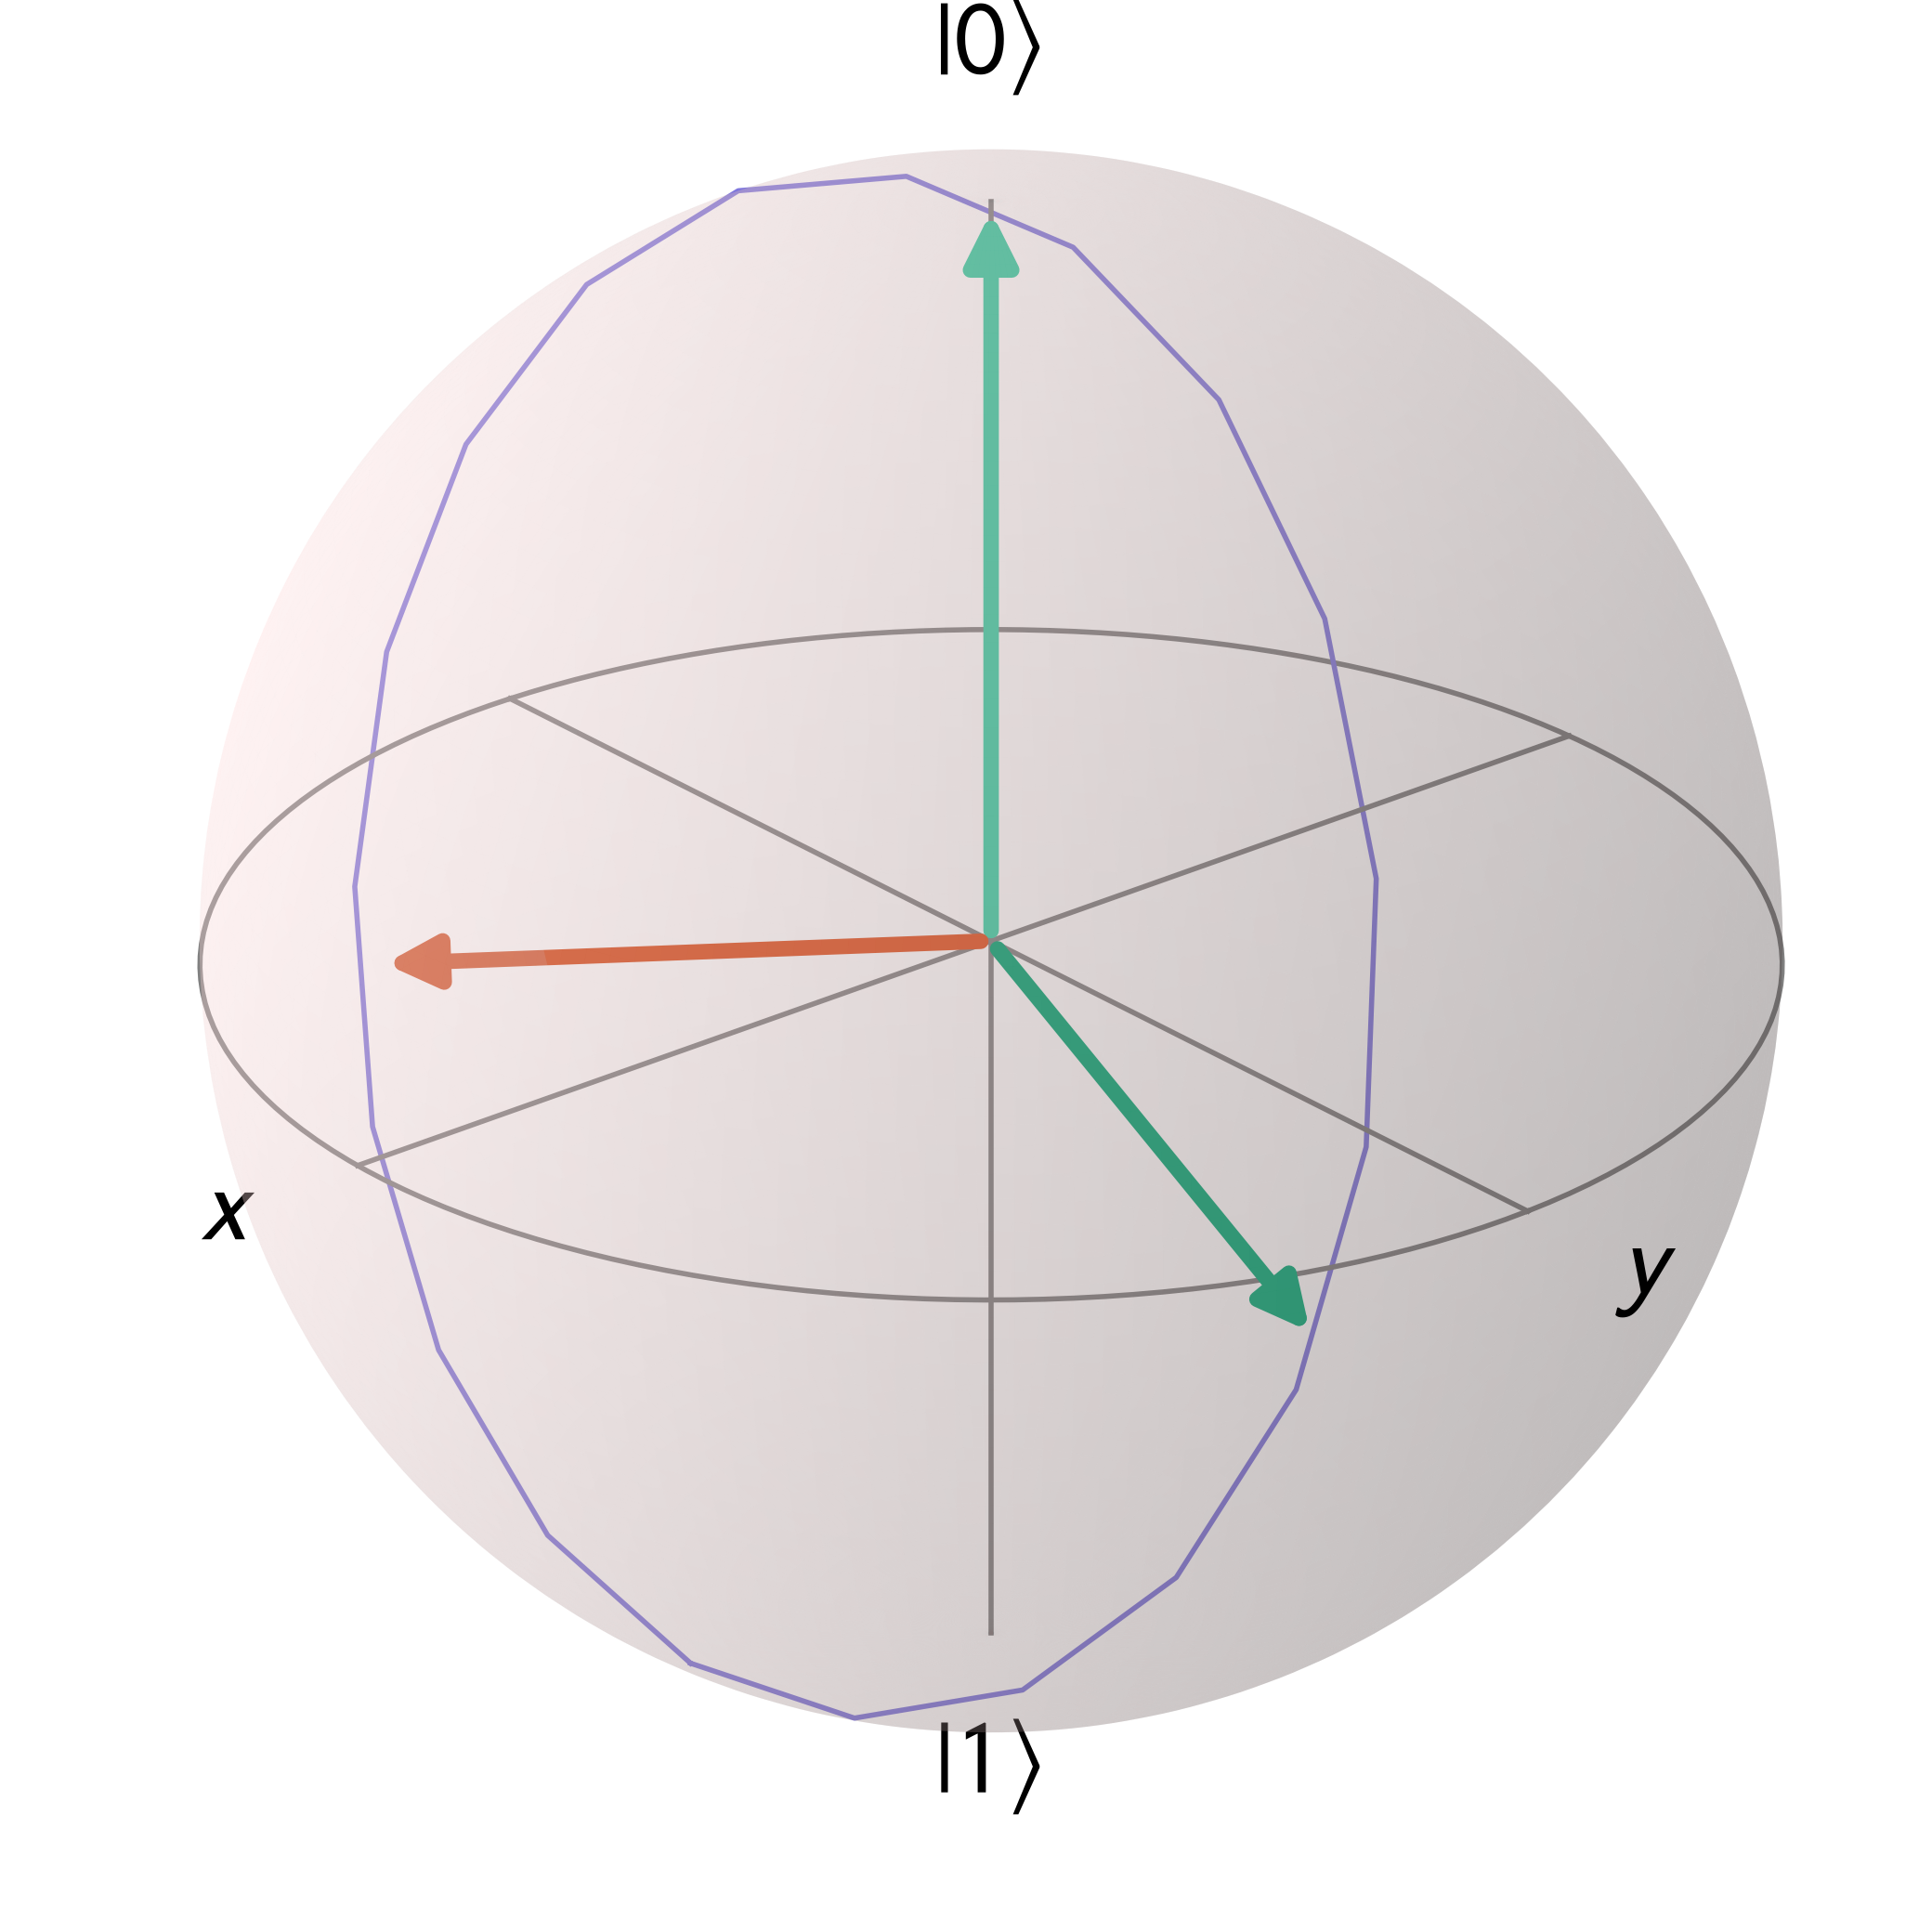

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import Bloch

# ------------------------------------------------------------------
# Geometry, matching the drawing
# ------------------------------------------------------------------
theta = np.deg2rad(75)          # tilt of R from the z-axis (= arctan(Hx/Hz))
epsilon = np.deg2rad(10)
# the field / precession axis:  R-hat = (sin theta, 0, cos theta)
R  = [np.sin(theta), 0, np.cos(theta)]

# initial Bloch vector: |0> sitting at the north pole
n0 = [0, 0, 1]

# ------------------------------------------------------------------
# The precession cone: circle of half-angle theta around R.
# Built from two unit vectors u, v that are perpendicular to R.
# ------------------------------------------------------------------
u = [np.cos(theta), 0, -np.sin(theta)]
v = [0, 1, 0]

# phi = np.linspace(np.pi, np.pi/2-epsilon,  20)
phi = np.linspace(0, 2*np.pi, 20)
xs = np.cos(theta) * R[0] + np.sin(theta) * (np.cos(phi) * u[0] + np.sin(phi) * v[0])
ys = np.cos(theta) * R[1] + np.sin(theta) * (np.cos(phi) * u[1] + np.sin(phi) * v[1])
zs = np.cos(theta) * R[2] + np.sin(theta) * (np.cos(phi) * u[2] + np.sin(phi) * v[2])

# n(t): one point on that circle (phi = 90 degrees)
phi_t = np.pi / 2 - epsilon
nt = [np.cos(theta) * R[0] + np.sin(theta) * (np.cos(phi_t) * u[0] + np.sin(phi_t) * v[0]),
      np.cos(theta) * R[1] + np.sin(theta) * (np.cos(phi_t) * u[1] + np.sin(phi_t) * v[1]),
      np.cos(theta) * R[2] + np.sin(theta) * (np.cos(phi_t) * u[2] + np.sin(phi_t) * v[2])]

# ------------------------------------------------------------------
# Draw it
# ------------------------------------------------------------------
fig = plt.figure(figsize=(5, 5))   # change figsize to control the size
b = Bloch(fig=fig)

# vectors, in the order added:  R,  n(0),  n(t)
b.vector_color = ['#d55a30', '#4cc3a0', '#1d9e75']
b.add_vectors(R)
b.add_vectors(n0)
b.add_vectors(nt)

# the precession circle, drawn as a line
b.point_color = ['#7f77dd']
b.add_points([xs, ys, zs], meth='l')
b.view = [-40,25]

# ---- tunable knobs ----
circle_alpha = 1.0    # reference-circle transparency: 0 = invisible, 1 = solid
axis_width   = 1.5    # x/y/z axis thickness (default was 1)
# -----------------------

b.frame_alpha = 0      # turn off the wireframe mesh
b._sphere_res = sphere_res
b.plot_back  = types.MethodType(_make_hemi((0, np.pi),   (-np.pi/2,   np.pi/2)),  b)
b.plot_front = types.MethodType(_make_hemi((-np.pi, 0),  (-3*np.pi/2, -np.pi/2)), b)

b.render()

# for line in list(b.axes.lines):
#     x, y, z = (np.asarray(a) for a in line.get_data_3d())
#     r = x**2 + y**2 + z**2
#     n = len(x)
#     if n > 2 and np.allclose(r, 1, atol=1e-3) and \
#        (np.allclose(x, 0, atol=1e-6) or np.allclose(z, 0, atol=1e-6)):
#         line.set_alpha(circle_alpha)       # the two reference circles
#     elif n == 2 and np.all(r > 0.5):
#         line.set_linewidth(axis_width)     # the x / y / z axes

for line in list(b.axes.lines):
    x, y, z = (np.asarray(a) for a in line.get_data_3d())
    if len(x) > 2 and np.allclose(x, 0, atol=1e-6) and \
       np.allclose(x**2 + y**2 + z**2, 1, atol=1e-3):
        line.remove()

plt.show()

# Fisher information

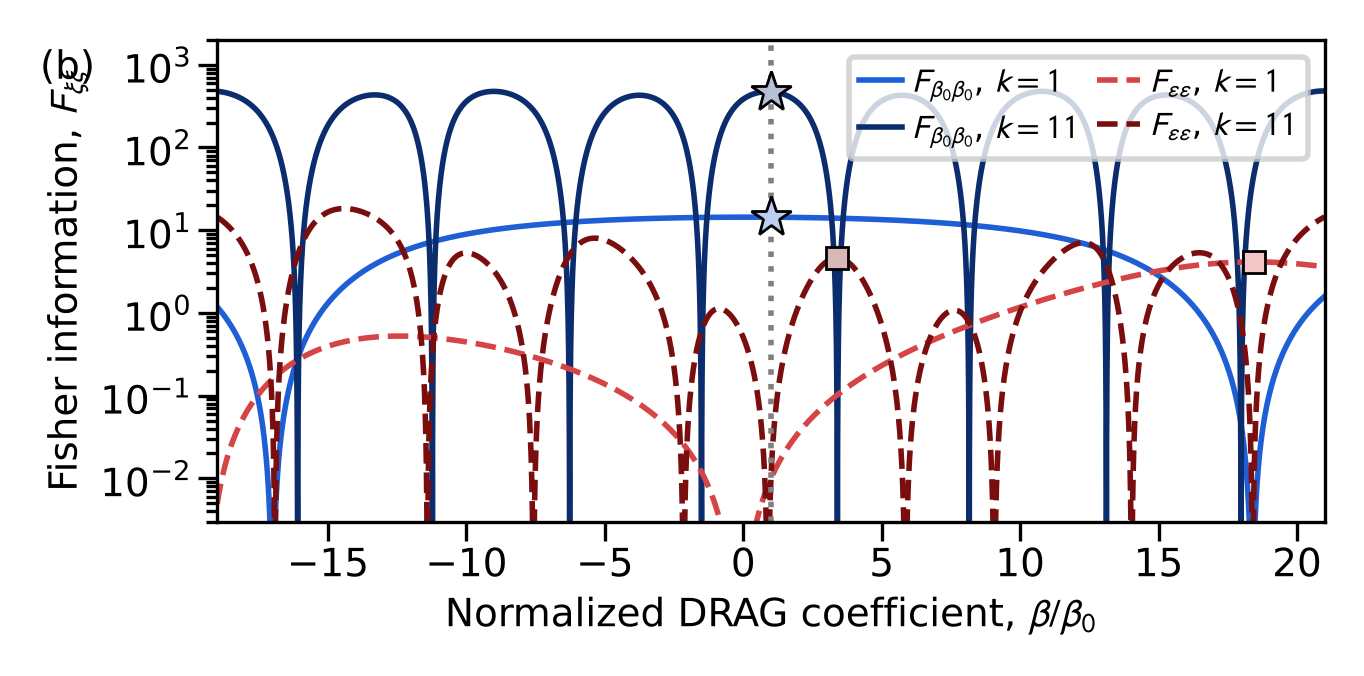

In [6]:
import fisher_information as fi 

N = 1.0          # per-shot
e = 0.05         # small nonzero epsilon so F_ee floor is finite/visible on a log axis
chi_beta0 = -0.02  # = chi*beta0 ; sets the horizontal scale (replace with your value)

d = np.linspace(-0.4, 0.4, 10001)
r = fi.beta_ratio(d, chi_beta0)          # beta/beta0

fig, ax = plt.subplots(figsize=(3.404, 3.404 * 0.5))
ax.plot(r, fi.fisher(1,  d, e, "delta", N), color=BLUE_LIGHT, label=r"$F_{\beta_0\beta_0}$, $k=1$")
ax.plot(r, fi.fisher(11, d, e, "delta", N), color=BLUE_DARK,  label=r"$F_{\beta_0\beta_0}$, $k=11$")
ax.plot(r, fi.fisher(1,  d, e, "eps",   N), color=RED_LIGHT, ls="--", label=r"$F_{\epsilon\epsilon}$, $k=1$")
ax.plot(r, fi.fisher(11, d, e, "eps",   N), color=RED_DARK,  ls="--", label=r"$F_{\epsilon\epsilon}$, $k=11$")

# locus delta=0 -> beta/beta0=1 (stars); delta=0.05 -> beta/beta0 markers (squares)
for k, c in [(1, BLUE_LIGHT), (11, BLUE_DARK)]:
    ax.plot(1.0, fi.Fdd_locus(k, e, N), "*", color=faded(c, LOCUS_ALPHA), ms=MS_STAR, zorder=5,
            mec=EDGE_COLOR, mew=EDGE_WIDTH)
rs1 = fi.beta_ratio(0.349, chi_beta0)
rs2 = fi.beta_ratio(0.048, chi_beta0)
ax.plot(rs1, fi.fisher(1,  0.349, e, "eps", N), "s", color=faded(RED_LIGHT, LOCUS_ALPHA), ms=MS_SQUARE, zorder=5, mec=EDGE_COLOR, mew=EDGE_WIDTH)
ax.plot(rs2, fi.fisher(11, 0.048, e, "eps", N), "s", color=faded(RED_DARK, LOCUS_ALPHA),  ms=MS_SQUARE, zorder=5, mec=EDGE_COLOR, mew=EDGE_WIDTH)

ax.axvline(1.0, color=REF_GRAY, lw=LW_REF, ls=":")
ax.set_yscale("log")
ax.set_ylim(3e-3, 2e3)
ax.set_xlim(r.min(), r.max())
ax.set_xlabel(r"Normalized DRAG coefficient, $\beta/\beta_0$")
ax.set_ylabel(r"Fisher information, $F_{\xi\xi}$")
ax.legend(loc="upper right", ncol=2, **LEGEND_KW)

ax.text(-0.16, 0.9, r"(b)", transform=ax.transAxes,
        fontsize=FS_PANEL, ha="left", va="bottom")
fig.tight_layout()
fig.savefig("./figures/main_fisherinformation.pdf", pad_inches=0.0)

## DRAPE experimental

In [7]:
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

In [8]:
data = np.load('./data/simulated/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11.npz', allow_pickle=True)

x = dl.to_physical(data['beta_range'])
y = data['drape_pops']
y_fit = data['y_fit']

print(data)
print(x.shape, y.shape, y_fit.shape)

NpzFile './data/simulated/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11.npz' with keys: beta_range, drape_pops, y_fit, ks
(500,) (11, 500, 4) (11, 500, 4)


In [9]:
epsilon_estimate = 0.0174
epsilon_error = 0.0015
beta0_estimate = -0.3894
beta0_error = 0.0003

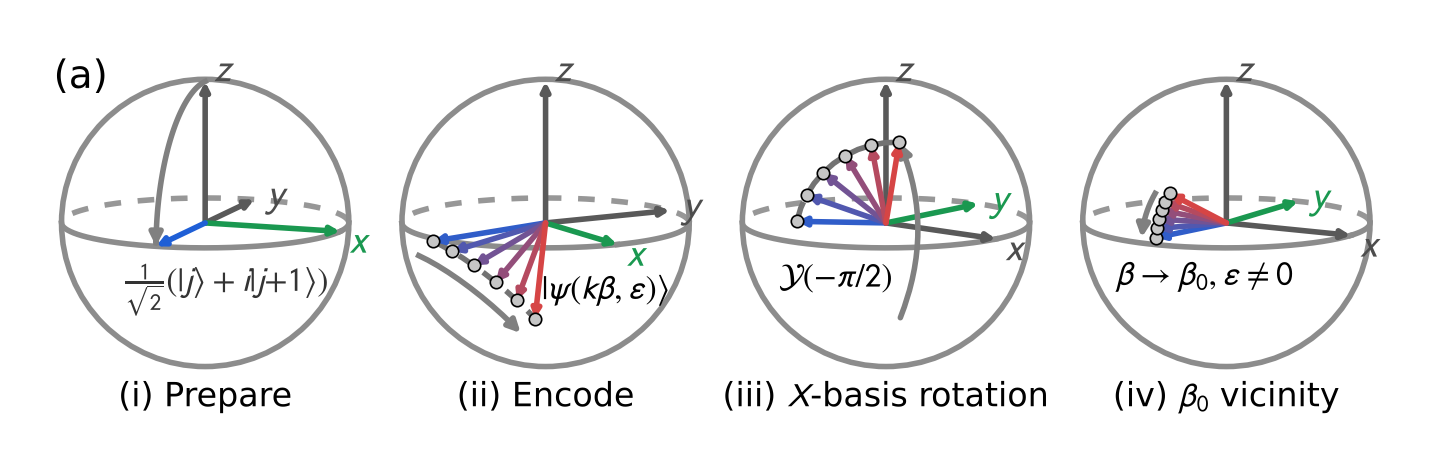

In [10]:
# ====================================================================
# DRAPE protocol — Bloch-sphere schematic (4-panel strip)
# Geometry is computed from the actual gate algebra (qutip).
# ====================================================================
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
import qutip as qt 

# ---- knobs ----------------------------------------------------------
NK    = 12              # number of pseudo-identity reps shown
FIG_W = 3.404
MS = 3
dl.GATE_DIM = 2            # 2x2 Pauli gates for the Bloch-sphere picture
ket0 = qt.basis(2, 0)      # = |j=1>, the measured ground
ket1 = qt.basis(2, 1)

# ---- DRAPE sequence: Y(pi/2) [X(-pi/2)X(pi/2)]^k X(pi/2) |j> --------
def amplify_states(eps, delta, kmax):
    """states after prepare and after each pseudo-identity rep (k=0..kmax)."""
    psi = dl.X_p2(eps, delta, 'plus') * ket0
    out = [psi]
    block = dl.X_p2(eps, delta, 'minus') * dl.X_p2(eps, delta, 'plus')   # pseudo-identity
    for _ in range(kmax):
        psi = block * psi
        out.append(psi)
    return out

def project_state(eps, delta, psi):
    return dl.Y_p2(eps, delta, 'minus') * psi

def bloch(psi):
    return np.array([qt.expect(qt.sigmax(), psi),
                     qt.expect(qt.sigmay(), psi),
                     qt.expect(qt.sigmaz(), psi)])

def angles(v):
    r = np.linalg.norm(v)
    return np.arccos(np.clip(v[2] / r, -1, 1)), np.arctan2(v[1], v[0])

def prepared_state(eps, delta):
    return dl.X_p2(eps, delta, 'plus') * ket0

# ---- orthographic Bloch projection ----------------------------------
AZ, EL = np.radians(35.0), np.radians(15.0)   # defaults; per-panel via set_view()
def set_view(az_deg, el_deg):
    """choose the camera azimuth / elevation of the *current* sphere."""
    global AZ, EL
    AZ, EL = np.radians(az_deg), np.radians(el_deg)

def proj(v):
    X, Y, Z = v
    X1 = X * np.cos(AZ) + Y * np.sin(AZ)
    Y1 = -X * np.sin(AZ) + Y * np.cos(AZ)
    sx = X1
    sy = Y1 * np.sin(EL) + Z * np.cos(EL)
    depth = Y1 * np.cos(EL) - Z * np.sin(EL)     # <0 = nearer viewer
    return sx, sy, depth

def sph(theta, phi):
    return np.array([np.sin(theta) * np.cos(phi),
                     np.sin(theta) * np.sin(phi), np.cos(theta)])
def p2(v): s = proj(v); return s[0], s[1]

XLIM  = (-1.15, 1.22)                         # tight data box around a sphere
YLIM  = (-1.40, 1.28)

def frame(ax):
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_aspect("equal"); ax.axis("off")

def draw_sphere(ax, rot_axis=None):
    """rot_axis in {'x','y','z',None}: highlight that axis green + thicker."""
    ax.add_patch(Circle((0, 0), 1.0, fill=False, lw=1, ec="0.55", zorder=1))
    ph = np.linspace(0, 2 * np.pi, 400)
    sx, sy, dep = proj(sph(np.full_like(ph, np.pi / 2), ph))
    def seg(mask, **kw):
        idx = np.where(mask)[0]
        if idx.size == 0: return
        for ch in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1):
            ax.plot(sx[ch], sy[ch], **kw)
    seg(dep <= 0, color="0.55", lw=1, zorder=2)
    seg(dep > 0, color="0.55", lw=1, ls=(0, (3, 3)), zorder=1, alpha=0.9)
    def axis_arrow(v, key, lab, dx=0, dy=0, ha="center"):
        x, y = p2(v)
        is_rot = (key == rot_axis)
        col = "#1a9850" if is_rot else "0.35"
        lw  = 1.0 if is_rot else 1.0
        ms  = MS
        zo  = 5 if is_rot else 3
        ax.add_patch(FancyArrowPatch((0, 0), (x, y), arrowstyle="-|>",
                     mutation_scale=MS, lw=lw, color=col, zorder=zo,
                     shrinkA=0, shrinkB=0))
        if lab:
            ax.text(x + dx, y + dy, lab, fontsize=FS_AXIS3D,
                    color=("#1a9850" if is_rot else "0.3"),
                    ha=ha, va="center", zorder=6)
    axis_arrow(sph(np.pi / 2, 0.0), 'x', r"$x$", dx=0.06, dy=-0.08, ha="left")
    axis_arrow(sph(np.pi / 2, np.pi / 2), 'y', r"$y$", dx=0.08, dy=0.02, ha="left")
    axis_arrow(np.array([0, 0, 1.0]), 'z', r"$z$", dx=0.06, dy=0.07, ha="left")  # north pole -> z
    frame(ax)

def vec(ax, v, color, lw=1, ms=MS, z=7, alpha=1.0):
    x, y = p2(v)
    ax.add_patch(FancyArrowPatch((0, 0), (x, y), arrowstyle="-|>",
                 mutation_scale=ms, lw=lw, color=color, zorder=z,
                 shrinkA=0, shrinkB=0, alpha=alpha))
    return x, y

def equator_arc(ax, phi0, phi1, **kw):
    ph = np.linspace(phi0, phi1, 40)
    sx, sy, _ = proj(sph(np.full_like(ph, np.pi / 2), ph))
    ax.plot(sx, sy, **kw)
    return sx, sy

def meridian_arc(ax, phi, t0, t1, **kw):
    t = np.linspace(t0, t1, 60)
    sx, sy, _ = proj(sph(t, np.full_like(t, phi)))
    ax.plot(sx, sy, **kw)
    return sx, sy

WSPACE = 0
MARG  = dict(left=0, right=1, bottom=0, top=1)

fig = plt.figure(figsize=(FIG_W, 0.3*FIG_W))
gs = fig.add_gridspec(1, 4, wspace=0, **MARG)
axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
cols = k_colors(NK)

EPS = 0.01
DELTA = 0.05

# ---- (a) prepare -----------------------------------------------------
set_view(20,10)                          # <-- per-sphere camera (a)
ax = axes[0]; draw_sphere(ax, rot_axis='x')   # <-- rotation axis (a)
v_prep = bloch(prepared_state(0, 0))
v_ideal = bloch(prepared_state(0, 0.0))            # delta=0 reference
th_p, ph_p = angles(v_prep); _, ph_id = angles(v_ideal)
# meridian guide arrow: z-axis arrow head (north pole) -> prepared-state arrow head
t = np.linspace(0.0, th_p, 60)
mx, my, _ = proj(sph(t, np.full_like(t, ph_p)))
ax.plot(mx[:-1], my[:-1], color="gray", lw=1.0, zorder=4)   # curve, minus the tip
ax.add_patch(FancyArrowPatch((mx[-2], my[-2]), (mx[-1], my[-1]),
             arrowstyle="-|>", mutation_scale=MS*1.5, lw=1.0,
             color="gray", zorder=4, shrinkA=0, shrinkB=0))
# X(pi/2) trajectory (continuous angle through the dressed gate)
# a = np.linspace(0, np.pi / 2 + 0, 60)
# traj = np.array([bloch(dl.Z_phase(0) * (-1j * ai / 2 * qt.sigmax()).expm()
#                        * dl.Z_phase(0) * ket0) for ai in a])
# ax.plot(*np.array([p2(v) for v in traj]).T, color="0.45", lw=1, ls='dashed', zorder=4)
# vec(ax, np.array([0, 0, 1.0]), 'gray', lw=1, ms=5, z=5, alpha=0.8)   # initial |j>
vec(ax, v_prep, cols[0], lw=1, ms=MS)                                           # prepared
# state-vector labels
# jx, jy = p2(np.array([0, 0, 0.5]))
# ax.text(jx - 0.06, jy, r"$|j\rangle$", fontsize=FS_SMALL,
#         color="0.2", ha="right", va="center", zorder=8)
px, py = p2(v_prep)
ax.text(px-0.23, py - 0.12, r"$\frac{1}{\sqrt{2}}(|j\rangle+i|j{+}1\rangle)$", fontsize=FS_SMALL,
        color="0.2", ha="left", va="top", zorder=8)
ax.text(0, -1.1, r"(i) Prepare", fontsize=FS_TITLE, ha="center", va="top")
# ax.text(-0.7, 1.1, r"(a)", fontsize=FS_TITLE, ha="center", va="top")

# ---- (b) amplify (xk) -----------------------------------------------
set_view(60, 10)                          # <-- per-sphere camera (b)
ax = axes[1]; draw_sphere(ax, rot_axis='x')   # <-- rotation axis (b)
states = amplify_states(EPS, DELTA, NK)
V = np.array([bloch(s) for s in states])
P = np.array([p2(v) for v in V])
P_b = P.copy()                       # panel (b) projected arrow-tip positions
ax.plot(P[1:-1, 0], P[1:-1, 1], color="0.45", lw=1.0, ls='dashed', zorder=5)
# copy of the dashed trajectory, displaced and capped with an arrowhead
DX, DY = -0.10, -0.10                               # rigid displacement
Pa = P[1:-1] + np.array([DX, DY])
ax.plot(Pa[:-1, 0], Pa[:-1, 1], color="gray", lw=1.0, zorder=5)
ax.add_patch(FancyArrowPatch(Pa[-2], Pa[-1], arrowstyle="-|>",
             mutation_scale=MS*1.5, lw=1.0, color="gray", zorder=5,
             shrinkA=0, shrinkB=0))

for j, v in enumerate(V):
    if (j % 2) != 0:
        c = cols[min(j, NK - 1)]
        vec(ax, v, c, lw=1.0, ms=MS, z=6 + j)             # arrow per scatter point
        ax.scatter(*p2(v), s=BLOCH_SCATTER_S, facecolors=faded('gray', BLOCH_SCATTER_ALPHA),
                edgecolors=EDGE_COLOR, linewidths=BLOCH_SCATTER_LW, zorder=20 + j)
    else:
        continue

# vec(ax, V[-1], cols[-1], lw=1.0)
ph0, phN = angles(V[0])[1], angles(V[-1])[1]
sxa, sya = equator_arc(ax, ph0, phN, color="#b03030", lw=0, zorder=6)
ax.text(sxa[len(sxa)//2]+0.9, sya[len(sya)//2] - 0.2, r"$|\psi(k\beta, \epsilon)\rangle$",
        fontsize=FS_SMALL, color="black", ha="center", va="top")
ax.text(0, -1.1, r"(ii) Encode", fontsize=FS_TITLE, ha="center", va="top")

# ---- (c) rotate basis (xk) -----------------------------------------------
set_view(40,10)                          # <-- per-sphere camera (b)
ax = axes[2]; draw_sphere(ax, rot_axis='y')   # <-- rotation axis (b)
states = amplify_states(EPS, DELTA, NK)
states_rot = []
for s in states:
    states_rot.append(dl.Y_p2(0, 0, 'minus')*s)
states = states_rot
V = np.array([bloch(s) for s in states])
P = np.array([p2(v) for v in V])
ax.plot(P[1:-1, 0], P[1:-1, 1], color="0.45", lw=1.0, ls='dashed', zorder=5)
for j, v in enumerate(V):
    if (j % 2) != 0:
        c = cols[min(j, NK - 1)]
        vec(ax, v, c, lw=1.0, ms=MS, z=6 + j)             # arrow per scatter point
        ax.scatter(*p2(v), s=BLOCH_SCATTER_S, facecolors=faded('gray', BLOCH_SCATTER_ALPHA),
                edgecolors=EDGE_COLOR, linewidths=BLOCH_SCATTER_LW, zorder=20 + j)
    else:
        continue
# vec(ax, V[-1], cols[-1], lw=1.0)
# connector arrow: n-th arrow tip from panel (b) -> n-th arrow tip in panel (c)
n = 11                        # visible arrows are the ODD indices: 1,3,5,7,9,11
ax.add_patch(FancyArrowPatch(np.array([0.1, -0.66]), P[n], arrowstyle="-|>",
             connectionstyle="arc3,rad=0.2",   # bow it like a meridian; flip sign to swap side
             mutation_scale=MS*1.5, lw=1.0, color="gray", zorder=5,
             shrinkA=0, shrinkB=0))
ph0, phN = angles(V[0])[1], angles(V[-1])[1]
sxa, sya = equator_arc(ax, ph0, phN, color="#b03030", lw=0, zorder=6)
ax.text(sxa[len(sxa)//2]-0.15, sya[len(sya)//2]-0.1, r"$\mathcal{Y}(-\pi/2)$",
        fontsize=FS_SMALL, color="black", ha="center", va="top")
ax.text(0, -1.1, r"(iii) $X$-basis rotation", fontsize=FS_TITLE, ha="center", va="top")

# ---- (d) sweep -----------------------------------------------
set_view(30, 10)                          # <-- per-sphere camera (b)
ax = axes[3]; draw_sphere(ax, rot_axis='y')   # <-- rotation axis (b)
states = amplify_states(EPS, DELTA/3, NK)
states_rot = []
for s in states:
    states_rot.append(dl.Y_p2(0, 0, 'minus')*s)
states = states_rot
V = np.array([bloch(s) for s in states])
P = np.array([p2(v) for v in V])
ax.plot(P[1:-1, 0], P[1:-1, 1], color="0.45", lw=1.0, ls='dashed', zorder=5)
# copy of the dashed trajectory, displaced and capped with an arrowhead (parallel guide)
DX, DY = -0.1, 0.0                            # rigid displacement
Pa = (P[1:-1] + np.array([DX, DY]))      # reversed
ax.plot(Pa[2:, 0], Pa[2:, 1], color="gray", lw=1.0, zorder=5)   # body, minus last few
ax.add_patch(FancyArrowPatch(Pa[2], Pa[0], arrowstyle="-|>",     # span last 3 pts
             mutation_scale=MS*1.5, lw=1.0, color="gray", zorder=5,
             shrinkA=0, shrinkB=0))
for j, v in enumerate(V):
    if (j % 2) != 0:
        c = cols[min(j, NK - 1)]
        vec(ax, v, c, lw=1.0, ms=MS, z=6 + j)             # arrow per scatter point
        ax.scatter(*p2(v), s=BLOCH_SCATTER_S, facecolors=faded('gray', BLOCH_SCATTER_ALPHA),
                edgecolors=EDGE_COLOR, linewidths=BLOCH_SCATTER_LW, zorder=20 + j)
    else:
        continue
# vec(ax, V[-1], cols[-1], lw=1.0)
ph0, phN = angles(V[0])[1], angles(V[-1])[1]
sxa, sya = equator_arc(ax, ph0, phN, color="#b03030", lw=0, zorder=6)
ax.text(sxa[len(sxa)//2]+0.3, sya[len(sya)//2] - 0.1, r"$\beta\to\beta_0, \epsilon\neq 0$",
        fontsize=FS_SMALL, color="black", ha="center", va="top")
ax.text(0, -1.1, r"(iv) $\beta_0$ vicinity", fontsize=FS_TITLE, ha="center", va="top")
axes[0].text(0.04, 0.95, r"(a)", transform=axes[0].transAxes,
             fontsize=FS_PANEL, ha="left", va="top")
# fig.savefig("./figures/main_drape_bloch.pdf", bbox_inches=None, pad_inches=0.00)
plt.show()

/tmp/ipykernel_843/3103210022.py:115: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect, connectors = ax.indicate_inset_zoom(axins, edgecolor=EDGE_COLOR, lw=EDGE_WIDTH, alpha=1, zorder=20)


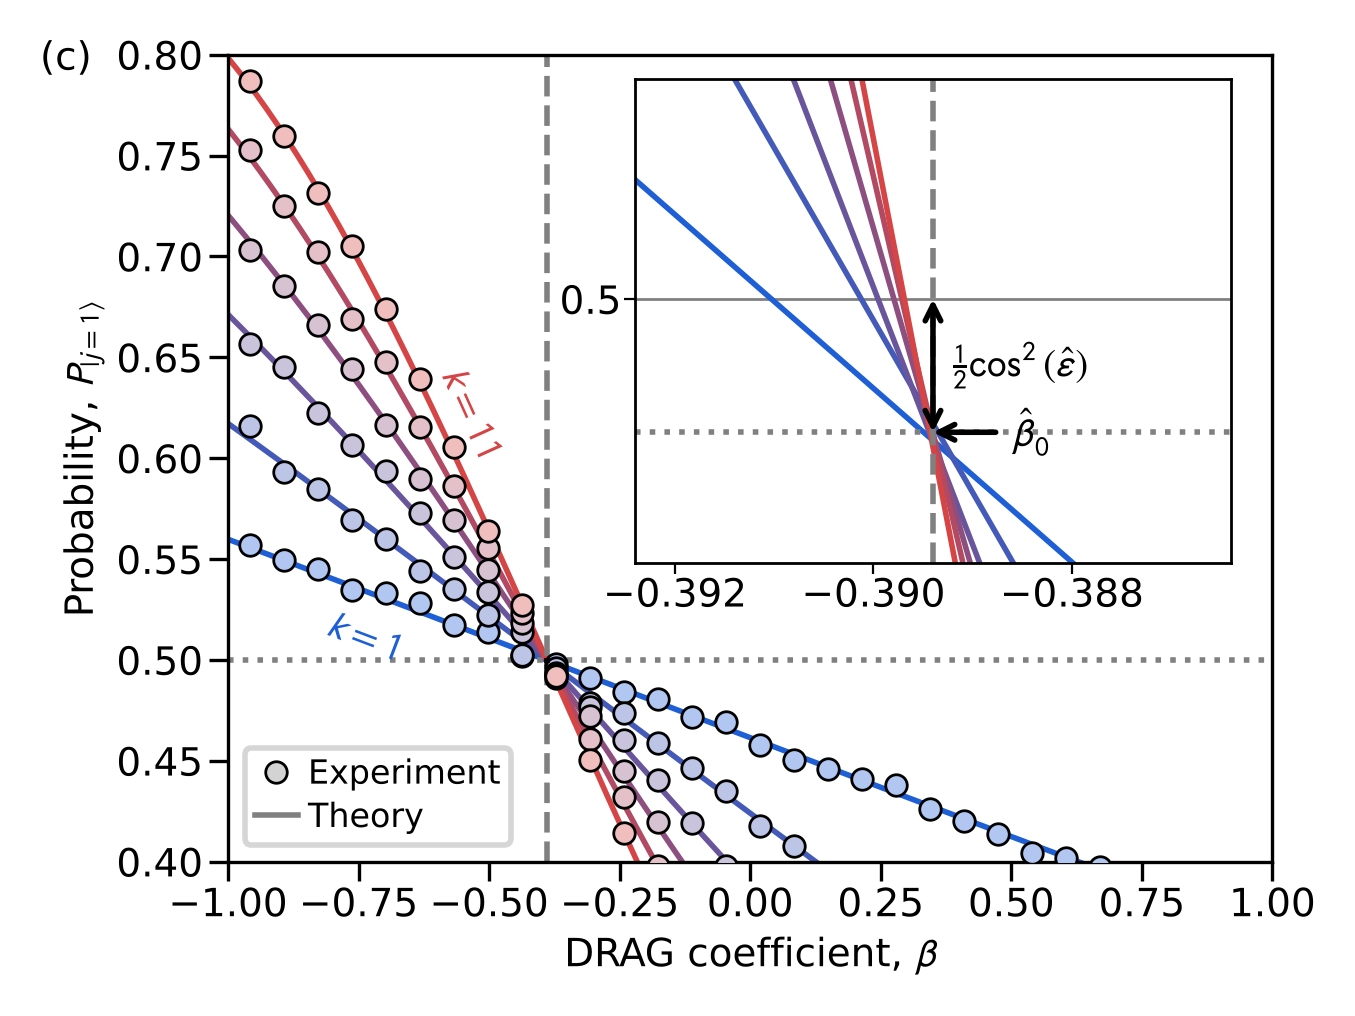

In [11]:
fig, ax = plt.subplots(figsize=(3.404, 3.404 * 0.75))

colors = k_colors(y.shape[0])                # blue -> red across k
for i in range(y.shape[0]):
    if (i % 2) == 0:
        color = colors[i]

        ax.scatter(
            x[::10],
            y[i][:, 2][::10],
            s=MS_SCATTER,
            facecolors=faded(color, SCATTER_ALPHA),       # opaque faded interior (Fig 1)
            edgecolors=EDGE_COLOR,               # thin black outline (Fig 1)
            linewidth=EDGE_WIDTH,
            zorder=10,
        )

        ax.plot(x, y_fit[i][:, 2], color=color)
    else:
        continue


# ax.axhline(0.5, color="gray", ls="--")
ax.set_xlim(-1, 1)
ax.set_ylim(0.4, 0.8)
ax.axvline(beta0_estimate, color=REF_GRAY, lw=LW_REF, ls="dashed")
ax.axhline(np.cos(epsilon_estimate)**2/2, color=REF_GRAY, lw=LW_REF, ls=":")
ax.set_xlabel(r"DRAG coefficient, $\beta$")
ax.set_ylabel(r"Probability, $P_{|j=1\rangle}$")
# Single legend entry each for data points and theory curves
handles, labels = ax.get_legend_handles_labels()
data_proxy = Line2D(
    [0], [0], marker='o', linestyle='None',
    markerfacecolor=faded('gray', SCATTER_ALPHA),     # match scatter faded interior
    markeredgecolor=EDGE_COLOR, markeredgewidth=EDGE_WIDTH,
    markersize=MS_SCATTER**0.5,                      # match scatter s=15 (area -> diameter)
)
theory_proxy = Line2D([0], [0], color='gray', lw=LW_MAIN)
handles += [data_proxy, theory_proxy]
labels += ['Experiment', 'Theory']
ax.legend(handles, labels, loc='lower left', **LEGEND_KW)
# ax.text(-1.3, 0.81, r"(f)", fontsize=FS_ANNOT, ha="center", va="top")

# Inline labels riding along the k=1 and k=11 curves to signify increasing k
def label_along_line(ax, xdata, ydata, text, xpos, color, va='bottom', dy=0.0):
    idx = int(np.clip(np.argmin(np.abs(xdata - xpos)), 0, len(xdata) - 2))
    xi, yi = xdata[idx], ydata[idx]
    angle = np.degrees(np.arctan2(ydata[idx + 1] - ydata[idx],
                                  xdata[idx + 1] - xdata[idx]))
    ax.text(xi, yi + dy, text, color=color, fontsize=FS_INLINE,
            rotation=angle, rotation_mode='anchor',
            transform_rotates_text=True, ha='center', va=va, zorder=15)

label_along_line(ax, x, y_fit[0][:, 2],  r'$k=1$',  xpos=-0.75, color=colors[0], va='bottom', dy=-0.034)
label_along_line(ax, x, y_fit[-1][:, 2], r'$k=11$', xpos=-0.5,
                 color=colors[-1], va='top', dy=0.06)

axins = ax.inset_axes([0.39, 0.37, 0.57, 0.6])   # [left, bottom, w, h] in axes fraction
for i in range(y.shape[0]):
    if (i%2) == 0:
        color = colors[i]
        line, = axins.plot(x, y_fit[i][:, 2], color=color)
        # axins.scatter(x, y[i][:, 2], s=MS_SCATTER,
        #     facecolors=faded(color, SCATTER_ALPHA),       # opaque faded interior (Fig 1)
        #     edgecolors=EDGE_COLOR,               # thin black outline (Fig 1)
        #     linewidths=EDGE_WIDTH,
        #     zorder=10)
    else:
        continue
axins.axhline(np.cos(epsilon_estimate)**2/2, color=REF_GRAY, lw=LW_REF, ls=":")
axins.axvline(beta0_estimate, color=REF_GRAY, lw=LW_REF, ls="dashed")
axins.set_xlim(beta0_estimate-0.003, beta0_estimate+0.003)
axins.set_ylim(0.4997, 0.50025)
axins.axhline(0.5, color='gray', lw=0.5, zorder=1)
axins.tick_params(labelsize=FS_ANNOT, length=2, width=0.4, pad=0.5)
axins.set_yticks([0.5])
# axins.grid(True)
# axins.legend(loc='upper right', frameon=True, handlelength=1.5, handletextpad=0.3, columnspacing=0.5, borderpad=0.3)
for sp in axins.spines.values():
    sp.set_linewidth(LW_INSET_SPINE)

# Double-headed arrow marking the gap between 0.5 and cos^2(eps)/2 in the inset
y_hi = 0.5
y_lo = np.cos(epsilon_estimate)**2 / 2
x_arr = beta0_estimate        # x position inside the inset; tweak to taste

axins.annotate(
    "", xy=(x_arr, y_hi), xytext=(x_arr, y_lo),
    arrowprops=dict(arrowstyle="<->", color="black", lw=LW_ANNOT_ARROW,
                    shrinkA=0, shrinkB=0),
    zorder=16,
)
axins.text(
    x_arr + 0.00018, (y_hi + y_lo) / 2,
    r"$\frac{1}{2}\cos^2(\hat\epsilon)$",
    fontsize=FS_ANNOT, ha="left", va="center", zorder=16,
)
# Single-headed arrow from the \hat\beta_0 label to the vertical line
beta_label_x = x_arr + 0.0008
beta_label_y = (y_hi + y_lo) / 2 + 0.00013
beta_label_y = y_lo
axins.annotate(
    "", xy=(beta0_estimate, beta_label_y),      # head: on the axvline
    xytext=(beta_label_x, beta_label_y),        # tail: at the label
    arrowprops=dict(arrowstyle="->", color="black", lw=LW_ANNOT_ARROW,
                    shrinkA=3, shrinkB=0),       # shrinkA leaves a small gap after the text
    zorder=16,
)
axins.text(
    x_arr + 0.0008, y_lo,
    r"$\hat\beta_0$",
    fontsize=FS_ANNOT, ha="left", va="center", zorder=16,
)

rect, connectors = ax.indicate_inset_zoom(axins, edgecolor=EDGE_COLOR, lw=EDGE_WIDTH, alpha=1, zorder=20)
for c in connectors:
    c.set_visible(False)

ax.text(-0.18, 0.97, r"(c)", transform=ax.transAxes,
        fontsize=FS_PANEL, ha="left", va="bottom")
fig.tight_layout()
fig.savefig("./figures/main_drapepops.pdf", pad_inches=0.00)

# AAE and APE together

In [12]:
aae_data = np.load('./data/simulated/aae_21pts_0_40_0.2390_0.2363.npz')
aae_data_old = np.load('./data/measured/aae_21pts_0_40_0.2512.npz')

print(aae_data, aae_data_old)

NpzFile './data/simulated/aae_21pts_0_40_0.2390_0.2363.npz' with keys: arr_0, arr_1, arr_2 NpzFile './data/measured/aae_21pts_0_40_0.2512.npz' with keys: N, pop2


In [13]:
ape_data = np.load('./data/measured/ape_data.npz')

angle_swept = ape_data['angle_swept']
pe_pops = ape_data['pe_pops']

In [14]:
# Per-trace empirical noise standard deviations (measured from
# r[i] = y[i,:,2] - y_fit[i] on the drag_ape_data file).
EMPIRICAL_STD = np.array([0.00636, 0.00734, 0.00685, 0.00649, 0.00702, 0.00934,
                          0.00653, 0.00623, 0.00686, 0.00711, 0.00634, 0.00532,
                          0.00463, 0.00675, 0.00875, 0.00574, 0.00768, 0.00485,
                          0.00657, 0.00559, 0.00654, 0.00621, 0.00586, 0.00592])/2
print(EMPIRICAL_STD.shape)  # ≈ [0.00212, 0.00245, 0.00228, 0.00216, 0.00301, 0.00381, 0.00218, 0.00208, 0.00229]
POOLED_STD = float(np.sqrt((EMPIRICAL_STD**2).mean()))   # ≈ 0.00812

def add_noise(y_fit_i, sigma=None, i=None, rng=None):
    """
    Return y_fit_noisy[i] = y_fit[i] + Gaussian white noise.
 
    Parameters
    ----------
    y_fit_i : 1-D array, shape (N,)
        Clean fit values for one trace.
    sigma : float, optional
        Noise standard deviation. If None, use the per-trace empirical std
        when `i` is given, otherwise the pooled empirical std (~0.0081).
    i : int in {0,...,5}, optional
        Trace index used to look up the empirical std.
    rng : np.random.Generator, optional
        Pass for reproducibility (e.g. np.random.default_rng(0)).
 
    Returns
    -------
    y_fit_noisy_i : 1-D array, shape (N,)
    """
    if rng is None:
        rng = np.random.default_rng(0)   # fixed seed so the injected noise is reproducible
    if sigma is None:
        sigma = EMPIRICAL_STD[i] if i is not None else POOLED_STD
    return np.asarray(y_fit_i) + rng.normal(0.0, sigma, size=np.shape(y_fit_i))

(24,)


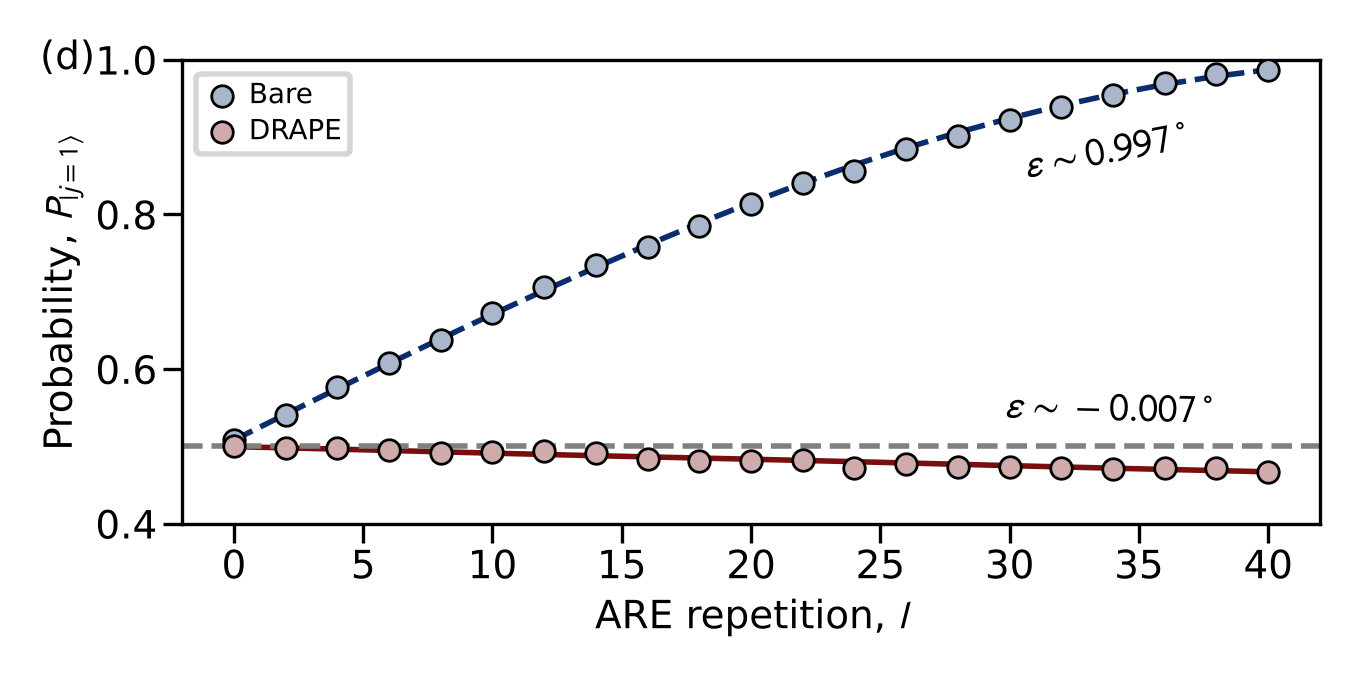

In [15]:
fig, ax = plt.subplots(figsize=(3.404, 3.404 * 0.5))
ax.scatter(aae_data['arr_0'], add_noise(aae_data['arr_1']), s=MS_SCATTER,
               facecolors=faded(BLUE_DARK, SCATTER_ALPHA), edgecolors=EDGE_COLOR, linewidth=EDGE_WIDTH,
               label='Bare', zorder=5)
ax.plot(aae_data['arr_0'], aae_data['arr_1'], color=BLUE_DARK, linestyle='dashed')
ax.scatter(aae_data['arr_0'], add_noise(aae_data['arr_2']), s=MS_SCATTER,
               facecolors=faded(RED_DARK, SCATTER_ALPHA), edgecolors=EDGE_COLOR, linewidth=EDGE_WIDTH,
               label='DRAPE', zorder=5)
ax.plot(aae_data['arr_0'], aae_data['arr_2'], color=RED_DARK)
ax.axhline(0.5, linestyle='--', color=REF_GRAY, lw=LW_REF)
label_along_line(ax, aae_data['arr_0'], aae_data['arr_1'], r'$\epsilon\sim 0.997^\circ$',  xpos=35, color='black', va='bottom', dy=-0.1)
label_along_line(ax, aae_data['arr_0'], aae_data['arr_2'], r'$\epsilon\sim -0.007^\circ$', xpos=35, color='black', va='top',    dy=0.1)

ax.set_ylim([0.4, 1.0])
ax.set_xlabel('ARE repetition, $l$')
ax.set_ylabel(r'Probability, $P_{|j=1\rangle}$')
ax.legend(fontsize=5, **LEGEND_KW)
ax.text(-0.125, 0.96, r"(d)", transform=ax.transAxes,
        fontsize=FS_PANEL, ha="left", va="bottom")
fig.tight_layout()
fig.savefig("./figures/main_aae.pdf", pad_inches=0.00)

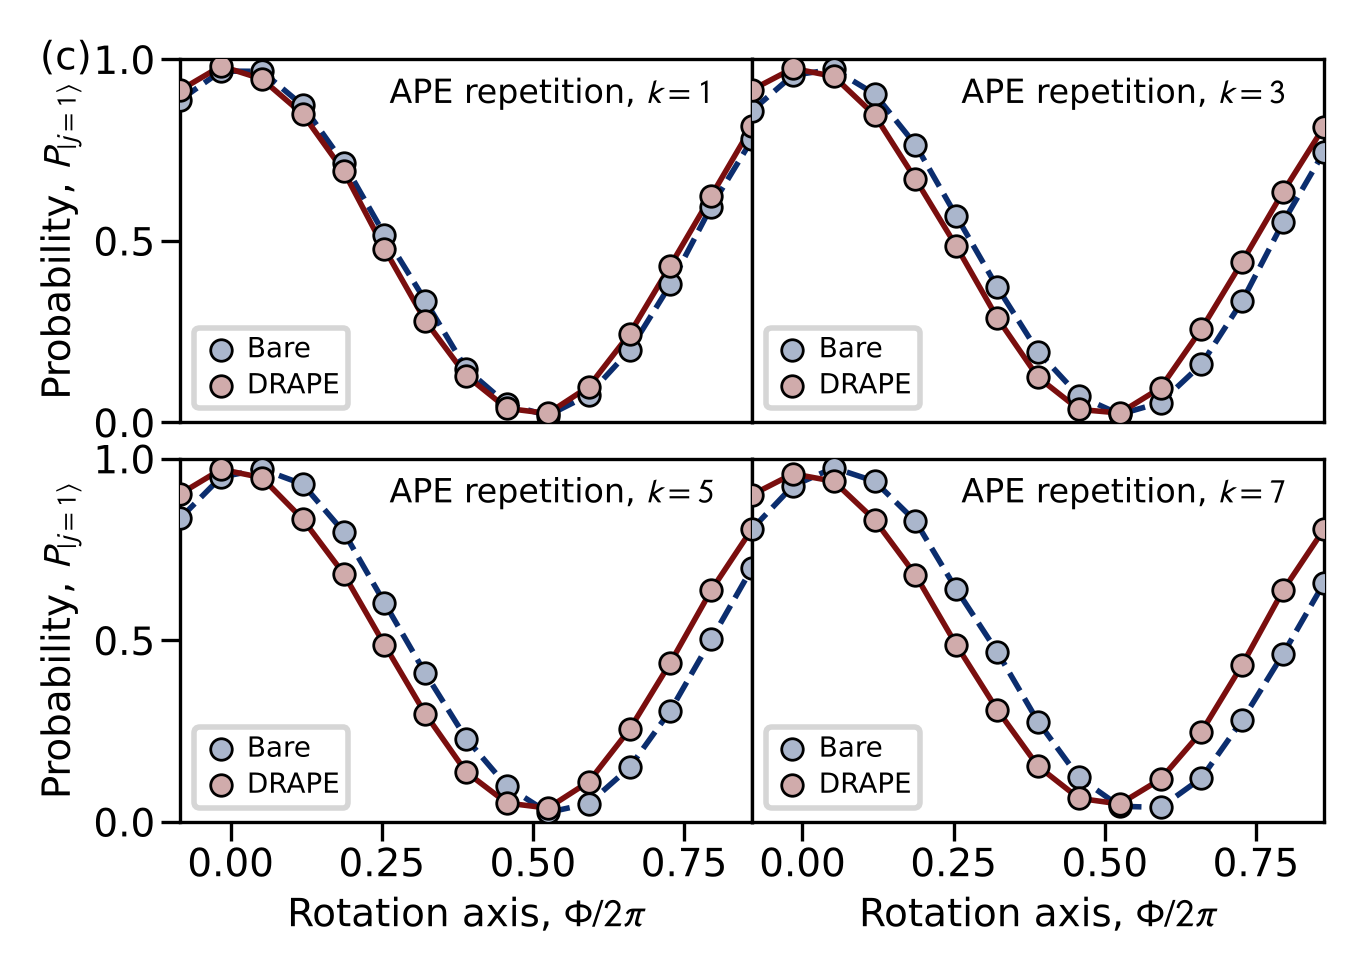

In [16]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(3.404, 3.404 * 0.7))       # 3. each row shares y

palette = k_colors(4)        # blue -> red across k = 1, 3, 5, 7

# (ax, palette/data index, k value) in grid order
panels = [
    (axes[0, 0], 0, 1),
    (axes[0, 1], 1, 3),
    (axes[1, 0], 2, 5),
    (axes[1, 1], 3, 7),
]
skip =5

for ax, i, k in panels:
    ax.scatter(angle_swept[::skip]/(2*np.pi), pe_pops[i][:, 0][::skip], s=MS_SCATTER, facecolor=faded(BLUE_DARK, SCATTER_ALPHA), edgecolors=EDGE_COLOR, linewidths=EDGE_WIDTH, label='Bare', zorder=5)
    ax.plot(angle_swept[::skip]/(2*np.pi), pe_pops[i][:, 0][::skip], color=faded(BLUE_DARK, 1), linestyle='dashed')
    ax.scatter(angle_swept[::skip]/(2*np.pi), pe_pops[i + 4][:, 0][::skip], s=MS_SCATTER, facecolor=faded(RED_DARK, SCATTER_ALPHA), edgecolors=EDGE_COLOR, linewidths=EDGE_WIDTH, label='DRAPE', zorder=10)
    ax.plot(angle_swept[::skip]/(2*np.pi), pe_pops[i+4][:, 0][::skip], color=faded(RED_DARK, 1))

    ax.set_title(f'APE repetition, $k={k}$', fontsize=FS_TITLE, x=0.65, y=1.0, pad=-8) 
    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xlim([angle_swept[::skip][0]/(2*np.pi), angle_swept[::skip][-1]/(2*np.pi)])
    ax.set_ylim([0, 1.0])
    ax.legend(loc='lower left', fontsize=5, **LEGEND_KW)

for ax in [axes[0,0], axes[1, 0]]:
    ax.set_yticks([0, 0.5, 1.0])
for ax in [axes[1,0], axes[1, 1]]:
    ax.set_xticks([0, 0.25, 0.5, 0.75])

# x label only on the bottom row (frees up vertical space between rows)
for ax in axes[-1, :]:
    ax.set_xlabel(r'Rotation axis, $\Phi/2\pi$')

# 3. y label once per row (left column)
for ax in axes[:, 0]:
    ax.set_ylabel(r'Probability, $P_{|j=1\rangle}$')
axes[0,0].text(-0.20, 1.0, r"(c)", transform=axes[0,0].transAxes,
        fontsize=FS_PANEL, ha="center", va="center")
fig.tight_layout()
fig.subplots_adjust(wspace=0.0, hspace=0.1, left=0.13, right=0.97, top=0.93, bottom=0.13)
fig.savefig("./figures/main_ape.pdf", pad_inches=0.00)

### Pulses

In [17]:
amp_uncorrected = 0.2512          # rough Rabi calibrated  ->  A-tilde
amp_corrected   = 0.85 * amp_uncorrected   # illustrative A < A-tilde
tg              = dl.DEFAULT_TG    # 20 ns
sigma           = tg / 4          # == dl.DEFAULT_SIGMA
beta_demo       = 0.1             # normalized units

# pulse 1: truncated Gaussian at A-tilde
train_tilde = {"clock": 0}
dl.add_pulse(train_tilde, "Gaussian", start=0, tg=tg, sigma=sigma,
             A=amp_uncorrected, beta=beta_demo)
 
# pulse 2: DRAG-corrected Gaussian at A
train_A = {"clock": 0}
dl.add_pulse(train_A, "Gaussian", start=0, tg=tg, sigma=sigma,
             A=amp_corrected, beta=beta_demo)

# ----- sample the genuine library waveforms ----------------------------------
tt = np.linspace(0, tg, 600)
Wx_tilde = np.array([dl.Omega_x(t, train_tilde) for t in tt])  # A-tilde Gaussian
Wx_A     = np.array([dl.Omega_x(t, train_A)     for t in tt])  # A Gaussian
Wy_A     = np.array([dl.Omega_y(t, train_A)     for t in tt])  # DRAG correction

c_env  = "#1f3a93"   # Omega_x  (in-phase / Gaussian)
xoff = tg + 5                 # horizontal offset for the 2nd pulse

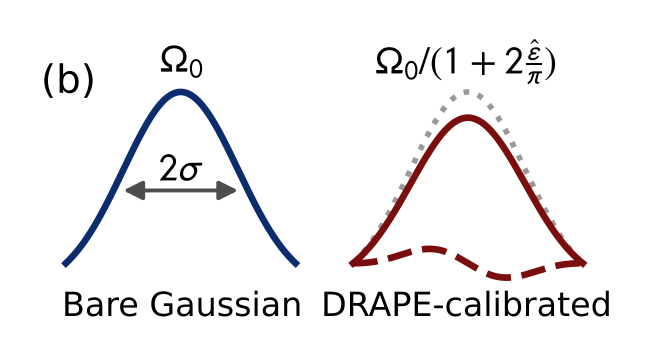

In [18]:
fig, ax = plt.subplots(figsize=(3.404*0.435, 3.404 * 0.25))

# Fix the axes box inside the figure. Reserve margins for the text:
#   top 18% for the Ω titles, bottom 22% for the BG/DG captions.
fig.subplots_adjust(left=0.02, right=0.98, top=0.82, bottom=0.22)

ax.plot(tt, Wx_tilde, color=BLUE_DARK, lw=1.2)
ax.plot(tt + xoff, Wx_tilde, color="0.6", lw=1.0, ls='dotted')
ax.plot(tt + xoff, Wx_A,     color=RED_DARK, lw=1.2)
ax.plot(tt + xoff, 5*Wy_A, color=RED_DARK, lw=1.2, ls='dashed')

ax.text(0.25, 1.1, r"$\Omega_0$", ha="center", va="center",
        fontsize=FS_TITLE+1, transform=ax.transAxes)
ax.text(0.75, 1.1, r"$\Omega_0/(1+2\frac{\hat\epsilon}{\pi})$", ha="center", va="center",
        fontsize=FS_TITLE+1, transform=ax.transAxes)
ax.text(0.25, -0.1, r"Bare Gaussian", ha="center", va="center",
        fontsize=FS_TITLE, transform=ax.transAxes)
ax.text(0.75, -0.1, "DRAPE-calibrated", ha="center", va="center",
        fontsize=FS_TITLE, transform=ax.transAxes)

mu = tg/2
x0, x1 = mu - sigma, mu + sigma
y = 0.5 * amp_corrected
ax.annotate("", xy=(x1, y), xytext=(x0, y),
            arrowprops=dict(arrowstyle="<|-|>", color="0.3", lw=0.7,
                            shrinkA=0, shrinkB=0))
ax.text((x0 + x1) / 2, y, r"$2\sigma$",
        ha="center", va="bottom", fontsize=FS_TITLE+1)

ax.axis("off")
ax.text(0.05, 1.0, r"(b)", transform=ax.transAxes,
        fontsize=FS_PANEL, ha="center", va="center")
fig.savefig("./figures/main_pulses.pdf",
            bbox_inches=None, pad_inches=0.00)

### APE and ARE circuits

In [19]:
from matplotlib.patches import Arc

def add_circuitARE_inset(ax, bbox=(-0.32, 0.0, 0.48, 0.34)):
    """Draw  |j=1> --( X_{pi/2} )^{2N+1} -- (measure)  as an inset.
    bbox = [x0, y0, width, height] in axes fractions."""
    cax = ax.inset_axes(bbox)
    cax.set_xlim(0, 100)
    cax.set_ylim(0, 100)
    cax.axis('off')
    cax.patch.set_visible(False)          # transparent background

    y = 48
    # input state
    cax.text(0, y, r'$|+y\rangle$', ha='left', va='center', fontsize=FS_SMALL)
    # qubit wire (covered by the white boxes where they sit on top)
    cax.plot([12, 100], [y, y], color='black', lw=0.8, zorder=1)

    # gate box
    gx, gw, gh = 16, 20, 50
    cax.add_patch(plt.Rectangle((gx, y - gh/2), gw, gh, facecolor='white',
                                edgecolor='black', lw=0.6, zorder=2))
    cax.text(gx + gw/2, y, r'$\mathcal{X}({\pi/2})$',
             ha='center', va='center', fontsize=FS_SMALL, zorder=3)
    
    cax.add_patch(plt.Rectangle((6+2*gx, y - gh/2), gw, gh, facecolor='white',
                                edgecolor='black', lw=0.6, zorder=2))
    cax.text(6+2*gx + gw/2, y, r'$\mathcal{X}({\pi/2})$',
             ha='center', va='center', fontsize=FS_SMALL, zorder=3)
    
    # # phi box
    # phix, phiw, phih = 62.5, 18, 50
    # cax.add_patch(plt.Rectangle((phix, y - phih/2), phiw, phih, facecolor='white',
    #                         edgecolor='black', lw=0.6, zorder=2))
    # cax.text(phix + phiw/2, y, r'$\Phi({-\pi/2})$',
    #          ha='center', va='center', fontsize=FS_SMALL, zorder=3)

    # large parenthesis around the box, with the exponent outside  ->  ( X )^{2N+1}
    btop, bbot = y + gh/2 + 10, y - gh/2 - 10    # paren extends past the box
    span = btop - bbot
    pw = 4                                      # parenthesis width (bulge)
    bl, br = gx, 6+2*gx + gw                # left / right paren x
    cax.add_patch(Arc((bl, y), pw, span, theta1=90,  theta2=270,
                      lw=0.5, zorder=3))         # (
    cax.add_patch(Arc((br, y), pw, span, theta1=-90, theta2=90,
                      lw=0.5, zorder=3))         # )
    cax.text(br + pw/2, btop+5, r'$l$', ha='left', va='center',
             fontsize=FS_SMALL, zorder=3)              # exponent

    # measurement box with meter symbol
    mx, mw, mh = 62.5, 16, 40
    cax.add_patch(plt.Rectangle((mx, y - mh/2), mw, mh, facecolor='white',
                                edgecolor='black', lw=0.6, zorder=2))
    cx, cy = mx + mw/2, y - mh/2 + 6
    cax.add_patch(Arc((cx, cy), mw*0.6, mh*0.6, theta1=0, theta2=180,
                      lw=0.8, zorder=3))
    cax.plot([cx, cx + mw*0.26], [cy, cy + mh*0.34],
             color='black', lw=0.8, zorder=3)   # needle
    return cax

def add_circuitAPE_inset(ax, bbox=(-0.32, 0.0, 0.48, 0.34)):
    """Draw  |j=1> --( X_{pi/2} )^{2N+1} -- (measure)  as an inset.
    bbox = [x0, y0, width, height] in axes fractions."""
    cax = ax.inset_axes(bbox)
    cax.set_xlim(0, 100)
    cax.set_ylim(0, 100)
    cax.axis('off')
    cax.patch.set_visible(False)          # transparent background

    y = 48
    # input state
    cax.text(0, y, r'$|+y\rangle$', ha='left', va='center', fontsize=FS_SMALL)
    # qubit wire (covered by the white boxes where they sit on top)
    cax.plot([12, 100], [y, y], color='black', lw=0.8, zorder=1)

    # gate box
    gx, gw, gh = 16, 20, 50
    cax.add_patch(plt.Rectangle((gx, y - gh/2), gw, gh, facecolor='white',
                                edgecolor='black', lw=0.6, zorder=2))
    cax.text(gx + gw/2, y, r'$\mathcal{X}({\pi/2})$',
             ha='center', va='center', fontsize=FS_SMALL, zorder=3)
    
    cax.add_patch(plt.Rectangle((6+2*gx, y - gh/2), gw, gh, facecolor='white',
                                edgecolor='black', lw=0.6, zorder=2))
    cax.text(6+2*gx + gw/2, y, r'$\mathcal{X}({-\pi/2})$',
             ha='center', va='center', fontsize=FS_SMALL, zorder=3)
    
    # phi box
    phix, phiw, phih = 62.5, 18, 50
    cax.add_patch(plt.Rectangle((phix, y - phih/2), phiw, phih, facecolor='white',
                            edgecolor='black', lw=0.6, zorder=2))
    cax.text(phix + phiw/2, y, r'$\Phi({-\pi/2})$',
             ha='center', va='center', fontsize=FS_SMALL, zorder=3)

    # large parenthesis around the box, with the exponent outside  ->  ( X )^{2N+1}
    btop, bbot = y + gh/2 + 10, y - gh/2 - 10    # paren extends past the box
    span = btop - bbot
    pw = 3                                      # parenthesis width (bulge)
    bl, br = gx, 6+2*gx + gw                # left / right paren x
    cax.add_patch(Arc((bl, y), pw, span, theta1=90,  theta2=270,
                      lw=0.5, zorder=3))         # (
    cax.add_patch(Arc((br, y), pw, span, theta1=-90, theta2=90,
                      lw=0.5, zorder=3))         # )
    cax.text(br + pw/2, btop+5, r'$k$', ha='left', va='center',
             fontsize=FS_SMALL, zorder=3)              # exponent

    # measurement box with meter symbol
    mx, mw, mh = 82, 16, 40
    cax.add_patch(plt.Rectangle((mx, y - mh/2), mw, mh, facecolor='white',
                                edgecolor='black', lw=0.6, zorder=2))
    cx, cy = mx + mw/2, y - mh/2 + 6
    cax.add_patch(Arc((cx, cy), mw*0.6, mh*0.6, theta1=0, theta2=180,
                      lw=0.8, zorder=3))
    cax.plot([cx, cx + mw*0.26], [cy, cy + mh*0.34],
             color='black', lw=0.8, zorder=3)   # needle
    return cax

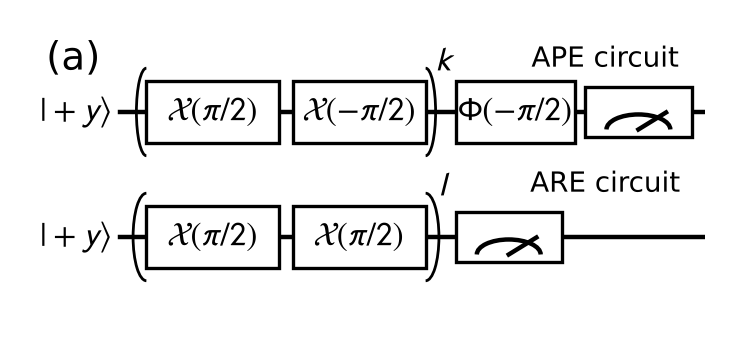

In [20]:
fig, ax = plt.subplots(figsize=(3.404*0.55, 3.404 * 0.25))
ax.axis("off")
add_circuitAPE_inset(ax, bbox=(0, 0.5, 1, 0.5))
add_circuitARE_inset(ax, bbox=(0, 0.0, 1, 0.5))
ax.text(0.05, 0.95, r"(a)", transform=ax.transAxes,
        fontsize=FS_PANEL, ha="center", va="center")
ax.text(0.85, 0.95, r"APE circuit", transform=ax.transAxes,
        fontsize=FS_PANEL-2, ha="center", va="center")
ax.text(0.85, 0.45, r"ARE circuit", transform=ax.transAxes,
        fontsize=FS_PANEL-2, ha="center", va="center")
fig.tight_layout()
fig.savefig("./figures/main_circuits.pdf",
            bbox_inches=None, pad_inches=0.00)